# Active nematics demo case

The source from the openpiv-users group: 

https://groups.google.com/g/openpiv-users/c/Us_q7h3Uri8/m/1p8XAYkHCQAJ

https://github.com/OpenPIV/openpiv-python-examples/blob/main/test18/active-nematics.gif

*Requires `openpiv>=0.26.0`. New in 0.26.0: `scipy.fft` default backend and optional `openpiv-rust` acceleration via `backend="rust"`/`"auto"`.*


In [ ]:
import importlib.metadata
print("openpiv", importlib.metadata.version("openpiv"))
# check Rust extension
try:
    import openpiv_rust
    print("openpiv-rust available")
except ImportError:
    print("openpiv-rust not installed — pip install openpiv[rust] for faster Rust backend")


In [9]:
from IPython.display import Image
Image('../test18/active-nematics.gif')

In [1]:
from openpiv import windef

    
from openpiv import tools, scaling, validation, filters, preprocess
import numpy as np
import pathlib


import matplotlib.pyplot as plt
%matplotlib inline

import matplotlib
matplotlib.rcParams['figure.figsize'] = (6.0, 6.0)

In [2]:
settings = windef.PIVSettings()


'Data related settings'
# Folder with the images to process
settings.filepath_images = pathlib.Path('../test18')
# Folder for the outputs
settings.save_path = pathlib.Path('../test18/')
# Root name of the output Folder for Result Files
settings.save_folder_suffix = 'Test_1'
# Format and Image Sequence
settings.frame_pattern_a = 'active-nematics0*.tif'
settings.frame_pattern_b = '(1+2),(3+4)'
# see documentation for more options. https://openpiv.readthedocs.io/en/latest/src/windef.html 

'Region of interest'
# (50,300,50,300) #Region of interest: (xmin,xmax,ymin,ymax) or 'full' for full image
settings.roi = 'full'

'Processing Parameters'
settings.correlation_method='linear' #'circular' or 'linear'
settings.normalized_correlation = True

settings.num_iterations = 3  # select the number of PIV passes
# add the interrogation window size for each pass. 
# For the moment, it should be a power of 2 

settings.windowsizes=(64, 32, 24, 8)
settings.overlap=(32, 16, 12, 4)

# settings.windowsizes = (128, 64, 32, 16, 8) # if longer than n iteration the rest is ignored
# The overlap of the interroagtion window for each pass.
# settings.overlap = (64, 32, 16, 8, 4) # This is 50% overlap

settings.show_plot = True
settings.scale_plot = 200  # select a value to scale the quiver plot of the vectorfield
# run the script with the given settings

settings.show_all_plots = False


Saving to ../test18/OpenPIV_results_24_Test_1/field_A0000.txt


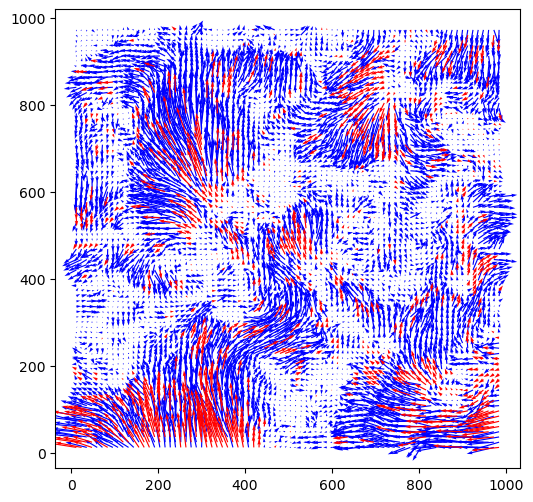

Image Pair 1
active-nematics0000 active-nematics0001
Saving to ../test18/OpenPIV_results_24_Test_1/field_A0001.txt


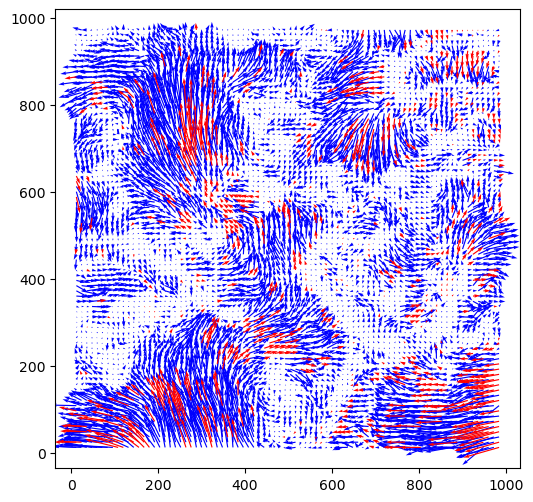

Image Pair 2
active-nematics0002 active-nematics0003
Saving to ../test18/OpenPIV_results_24_Test_1/field_A0002.txt


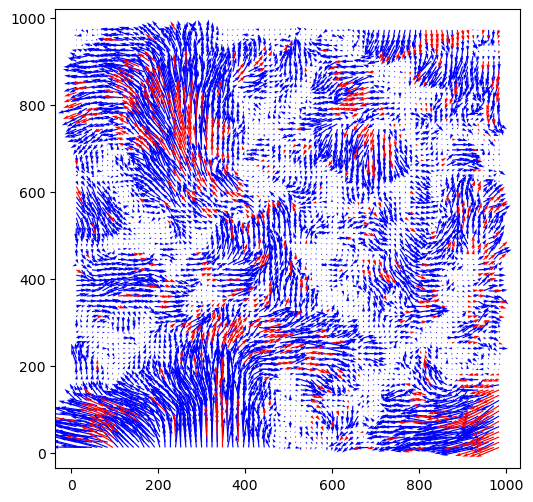

Image Pair 3
active-nematics0004 active-nematics0005
Saving to ../test18/OpenPIV_results_24_Test_1/field_A0003.txt


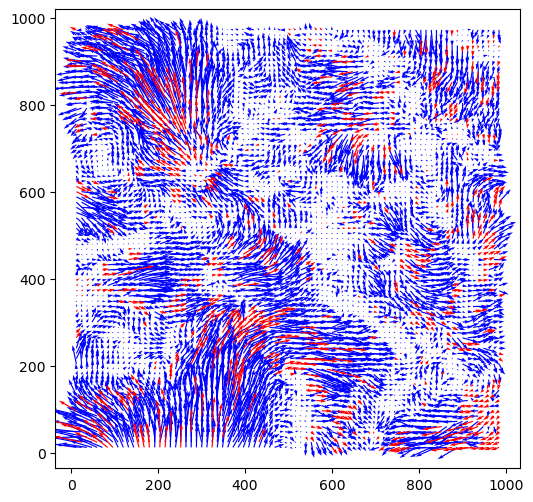

Image Pair 4
active-nematics0006 active-nematics0007
Saving to ../test18/OpenPIV_results_24_Test_1/field_A0004.txt


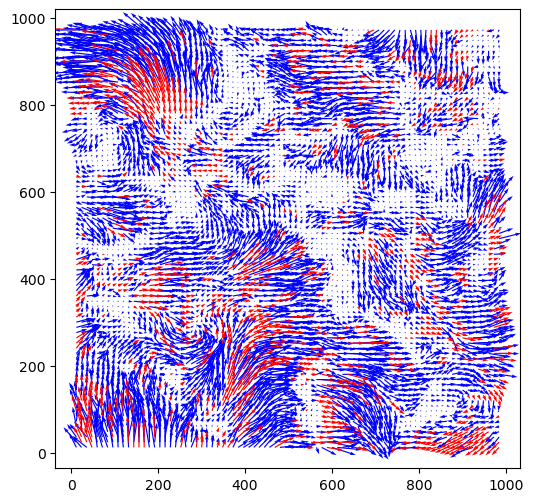

Image Pair 5
active-nematics0008 active-nematics0009


In [3]:
windef.piv(settings)